In [1]:
import pickle
import numpy as np

from scipy.stats import ks_2samp

In [2]:
names = [
         'Glacier',
         'GUT.ERP015450',
         'GUT.SRP056641',
         'Lake',
         'ORAL',
         'River',
         'Soil',
         'activatedsludge',]

In [5]:
for name in names:
    print(name)
    filtered_name = 'filtered_datasets/full_dataset.filtered.Grilli.{}.dat'.format(name)

    with open(filtered_name,'rb') as f:
        data = pickle.load(f)
        f.close()
        M,N= np.shape(data)
        print(N)

    r = N/M
    MP_min = (1-r**0.5)**2
    MP_max = (1+r**0.5)**2

    eigvals,eigvects = np.linalg.eigh(np.corrcoef(data.T))
    argsort = np.argsort(eigvals)
    eigvals = eigvals[argsort]; eigvects = eigvects[:,argsort]
    eigvals = eigvals[-(M-1):]; eigvects = eigvects[:,-(M-1):] #since r>1, remove 0-eigenvalues.

    mask = eigvals<MP_min
    LCs = eigvects[:,mask]
    IPRs = np.sum(LCs**4,axis=0)/(np.sum(LCs**2,axis=0)**2)
    N_eff_N = 1/IPRs/N

    # shuffles = 25
    # null_data = np.copy(data)
    # indices = np.arange(M)
    # null_N_effs = []
    # for i in range(shuffles):
    #     for sp in range(N):
    #         np.random.shuffle(indices)
    #         null_data[:,sp] = null_data[indices,sp] #shuffle taxon's abundances across samples
    #     null_eigvals,null_eigvects = np.linalg.eigh(np.corrcoef(null_data.T))
    #     null_argsort = np.argsort(null_eigvals)
    #     null_eigvals = null_eigvals[null_argsort]; null_eigvects = null_eigvects[:,null_argsort]
    #     null_eigvals = null_eigvals[-(M-1):]; null_eigvects = null_eigvects[:,-(M-1):]

    #     null_LCs = null_eigvects[:,:] #take all null eigvects, since by construction there will be no LCs in the null data
    #     null_IPRs = np.sum(null_LCs**4,axis=0)/(np.sum(null_LCs**2,axis=0)**2)
    #     null_N_eff_N = 1/null_IPRs/N
    #     null_N_effs.append(null_N_eff_N)

    # null_N_effs = np.array(null_N_effs).flatten()

    # res = ks_2samp(N_eff_N,null_N_effs)
    # print(np.shape(N_eff_N),np.shape(null_N_effs))
    # print(name,res)

    ### Check also N_eff against that of noisy components in the true datasets.
    noisy_mask = (eigvals>MP_min) & (eigvals<MP_max)
    noisy_comps = eigvects[:,noisy_mask]
    noisy_IPRs = np.sum(noisy_comps**4,axis=0)/(np.sum(noisy_comps**2,axis=0)**2)
    noisy_N_eff_N = 1/noisy_IPRs/N

    res = ks_2samp(N_eff_N,
                   noisy_N_eff_N)
    print(name,res)

    if name=='Soil':
        print(np.sum(mask),N_eff_N)

Glacier
1075
Glacier KstestResult(statistic=0.675, pvalue=0.009602010140440615, statistic_location=0.25298125405825506, statistic_sign=1)
GUT.ERP015450
2003
GUT.ERP015450 KstestResult(statistic=0.8074074074074075, pvalue=7.104253149846944e-26, statistic_location=0.20491111438912835, statistic_sign=1)
GUT.SRP056641
1005
GUT.SRP056641 KstestResult(statistic=0.6187683284457478, pvalue=3.68341960015341e-05, statistic_location=0.22798645034974988, statistic_sign=1)
Lake
869
Lake KstestResult(statistic=0.3136288998357964, pvalue=0.0004557691788467402, statistic_location=0.2570785838764903, statistic_sign=1)
ORAL
540
ORAL KstestResult(statistic=0.28771929824561404, pvalue=0.05118645309044433, statistic_location=0.24751361302984173, statistic_sign=1)
River
2011
River KstestResult(statistic=0.81704966641957, pvalue=7.790876414667917e-28, statistic_location=0.23414863029787897, statistic_sign=1)
Soil
561
Soil KstestResult(statistic=0.34505494505494505, pvalue=0.006442632366244455, statistic_loca

{'whiskers': [<matplotlib.lines.Line2D at 0x237897f88b0>,
 'caps': [<matplotlib.lines.Line2D at 0x237897f8df0>,
 'boxes': [<matplotlib.lines.Line2D at 0x237897f8610>],
 'medians': [<matplotlib.lines.Line2D at 0x23789805370>],
 'fliers': [<matplotlib.lines.Line2D at 0x23789805610>],
 'means': []}

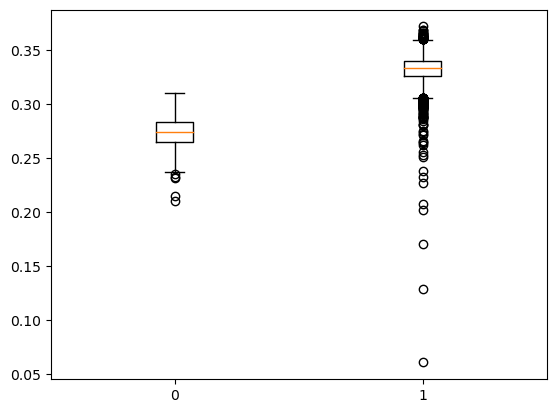

In [37]:
import matplotlib.pyplot as plt
fig,ax = plt.subplots()
ax.boxplot(N_eff_N,positions = [0])
ax.boxplot(null_N_effs,positions = [1])